# Queueing examples in Python

The Week 02 lecture examples, in Python. Run these cells after the slides:

1. Sampling exponential times (derivation notes, pp2–3)
2. The M/M/1 example, λ = 0.5 and μ = 4 (slides 15–16)
3. Costs: a faster or slower server (slides 18–21)
4. Three servers in series (slides 24–25)
5. Simulation against theory across ρ (derivation notes, Figures 10–11)

*Made for this site. The derivation notes say their code is "on Course Resources", but that code is not in the course
files, and neither are workbooks for slides 18–25. NumPy and Matplotlib only, so there is nothing to install.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)   # fixed seed; change it to see other runs

## 1. Sampling exponential times

If y is uniform on [0, 1], then x = −(1/λ) ln(y) has the exponential distribution with mean a = 1/λ. This is the Excel formula `-(1/λ)*LN(RAND())`, and the same as the notes' MATLAB code with a = 6.

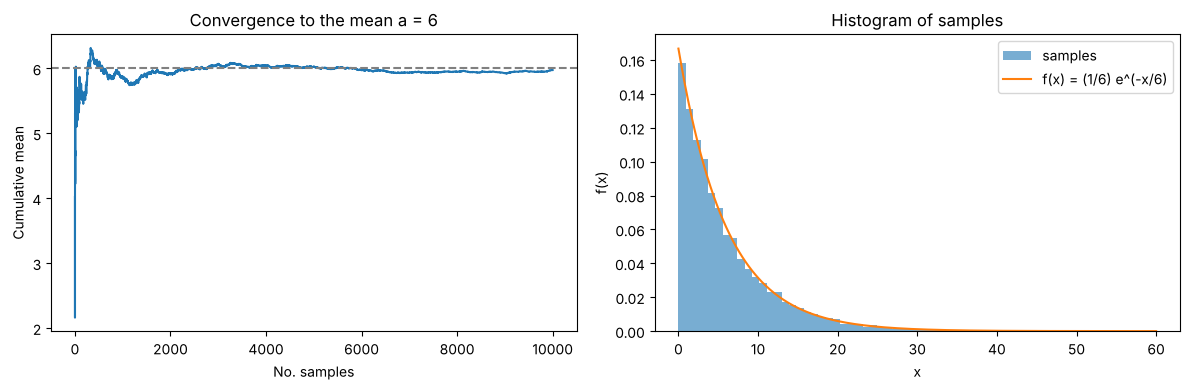

Sample mean 5.975 (theory 6)


In [2]:
a = 6; lam = 1 / a
X = -(1 / lam) * np.log(rng.random(10_000))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.cumsum(X) / np.arange(1, len(X) + 1)); ax[0].axhline(a, color="grey", ls="--")
ax[0].set(xlabel="No. samples", ylabel="Cumulative mean", title="Convergence to the mean a = 6")
ax[1].hist(X, bins=60, density=True, alpha=0.6, label="samples")
x = np.linspace(0, 60, 300); ax[1].plot(x, lam * np.exp(-lam * x), label="f(x) = (1/6) e^(-x/6)")
ax[1].set(xlabel="x", ylabel="f(x)", title="Histogram of samples"); ax[1].legend(); plt.tight_layout(); plt.show()
print(f"Sample mean {X.mean():.3f} (theory {a})")

## 2. The M/M/1 example: λ = 0.5, μ = 4 (per minute)

Formulas: W = λ/(μ(μ−λ)) in the queue, T = 1/(μ−λ) in the system, N = λ/(μ−λ) customers in the system. The simulation uses 100,000 customers.

In [3]:
def single_server(iat, service):
    """One FIFO server, the same recursion as the Excel sheets:
    Arrival(n) = Arrival(n-1) + IAT(n); Start(n) = max(Arrival(n), End(n-1)); End(n) = Start(n) + Service(n)."""
    arrival = np.cumsum(iat)
    start = np.empty_like(arrival); end = np.empty_like(arrival)
    prev_end = 0.0
    for n in range(len(arrival)):
        start[n] = max(arrival[n], prev_end)
        end[n] = start[n] + service[n]
        prev_end = end[n]
    wait = start - arrival                                    # time in queue
    idle = start - np.concatenate(([0.0], end[:-1]))          # server idle before each customer
    return arrival, start, end, wait, idle

lam, mu = 0.5, 4.0
W, T, N = lam / (mu * (mu - lam)), 1 / (mu - lam), lam / (mu - lam)
n = 100_000
arrival, start, end, wait, idle = single_server(rng.exponential(1 / lam, n), rng.exponential(1 / mu, n))
print(f"Time in queue   W: theory {W:.3f}  simulated {wait.mean():.3f} min")
print(f"Time in system  T: theory {T:.3f}  simulated {(end - arrival).mean():.3f} min")
print(f"No. in system   N: theory {N:.3f}  simulated {(end - arrival).sum() / end[-1]:.3f}  (Little: N = λT)")

Time in queue   W: theory 0.036  simulated 0.036 min
Time in system  T: theory 0.286  simulated 0.285 min
No. in system   N: theory 0.143  simulated 0.143  (Little: N = λT)


## 3. Costs: how fast should the server be?

Idle server: £0.50 per minute. A waiting customer: £1 per minute. 100 arrivals, λ = 0.5, μ = 4, 2 or 1. A single run
(like the slides) varies a lot, so the expected values come from 20,000 runs.

*Erratum C7: the slides say customers waited 4.5 minutes in total for μ = 2. That happens in under 1% of runs; the expected
total is about 16.5 minutes. The expected costs of μ = 4 and μ = 2 are almost equal.*

In [4]:
def cost_run(mu, n=100, lam=0.5):
    _, _, _, wait, idle = single_server(rng.exponential(1 / lam, n), rng.exponential(1 / mu, n))
    return idle.sum(), wait.sum()

print(f"{'mu':>4} {'one run: idle':>14} {'wait':>6} {'cost':>7} | {'expected idle':>13} {'wait':>6} {'cost':>7}")
for mu in (4, 2, 1):
    i1, w1 = cost_run(mu)
    runs = np.array([cost_run(mu) for _ in range(20_000)])
    ei, ew = runs.mean(axis=0)
    print(f"{mu:>4} {i1:>14.1f} {w1:>6.1f} {0.5 * i1 + w1:>7.1f} | {ei:>13.1f} {ew:>6.1f} {0.5 * ei + ew:>7.1f}")

  mu  one run: idle   wait    cost | expected idle   wait    cost


   4          149.7    2.7    77.5 |         175.3    3.5    91.2


   2          111.4   30.1    85.8 |         150.6   16.4    91.7


   1          120.8   85.6   146.0 |         101.8   96.7   147.6


## 4. Three servers in series

Jobs arrive on average every 10 minutes (exponential). Each of 3 stages takes Uniform(5, 7) minutes, and a job moves straight on when a stage is free. The slides' rough guess is 18 minutes (3 × 6 minutes of work). Random arrivals add some queueing at each stage, so the simulated time is a few minutes longer. The slides do not say how arrivals are distributed; exponential is assumed here.

In [5]:
def series(n_jobs, stages=((5, 7), (5, 7), (5, 7)), mean_iat=10):
    t = np.cumsum(rng.exponential(mean_iat, n_jobs))       # arrival times
    first_arrival = t.copy()
    for lo, hi in stages:
        _, start, end, _, _ = single_server(np.diff(np.concatenate(([0.0], t))), rng.uniform(lo, hi, n_jobs))
        t = end                                            # finishing one stage = arriving at the next
    return (t - first_arrival).mean()

for n in (100, 250, 500, 1000):
    print(f"{n:>5} jobs: average time in system {series(n):.2f} min")

  100 jobs: average time in system 23.29 min
  250 jobs: average time in system 26.34 min
  500 jobs: average time in system 22.73 min
 1000 jobs: average time in system 24.01 min


## 5. Simulation against theory across ρ

μ = 1, λ from 0.05 to 0.95. Mean number in the system N = ρ/(1−ρ) and mean time in the system T = 1/(μ−λ). The two curves agree until ρ approaches 1, where the queue needs very long runs to settle.

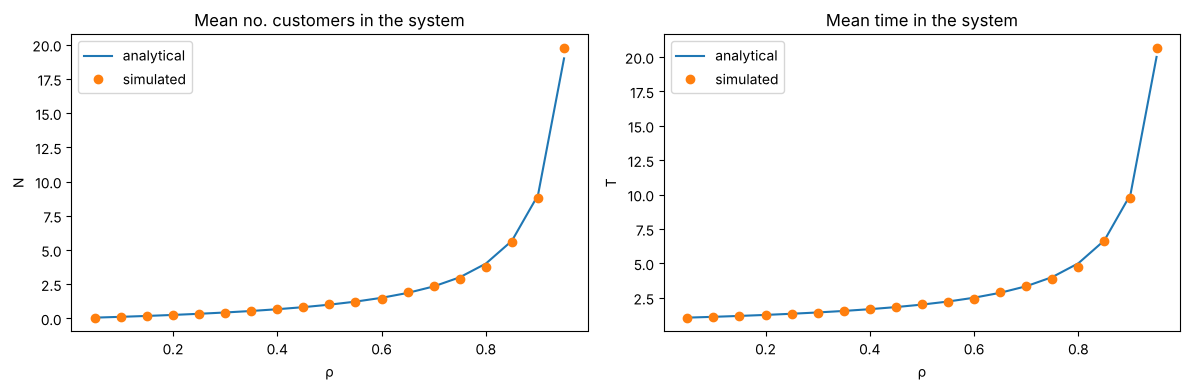

In [6]:
rhos = np.arange(0.05, 0.96, 0.05)
simN, simT = [], []
for rho in rhos:
    arrival, start, end, wait, idle = single_server(rng.exponential(1 / rho, 50_000), rng.exponential(1.0, 50_000))
    tis = end - arrival
    simT.append(tis.mean()); simN.append(tis.sum() / end[-1])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rhos, rhos / (1 - rhos), label="analytical"); ax[0].plot(rhos, simN, "o", label="simulated")
ax[0].set(xlabel="ρ", ylabel="N", title="Mean no. customers in the system"); ax[0].legend()
ax[1].plot(rhos, 1 / (1 - rhos), label="analytical"); ax[1].plot(rhos, simT, "o", label="simulated")
ax[1].set(xlabel="ρ", ylabel="T", title="Mean time in the system"); ax[1].legend()
plt.tight_layout(); plt.show()